# 基于沪深总成交额的注意力捕捉

**行为金融因子 —— 投资者注意力**

首先，统计每日沪深两市的总成交额，作为市场关注程度的代理指标：

$$
\text{mkt_vol}_d = \text{Vol}_{\text{SH},d} + \text{Vol}_{\text{SZ},d}
$$

其中，$\text{Vol}_{\text{SH},d}$ 为上海证券交易所所有股票在交易日 $d$ 的总成交额，$\text{Vol}_{\text{SZ},d}$ 为深圳证券交易所所有股票在交易日 $d$ 的总成交额。

进一步，将上述市场关注代理指标与个股日收益进行月度时序回归，回归方程如下：

$$
r_{i,d} = \mu_{i,t} + \beta_{i,t} \cdot \text{mkt_vol}_d + \rho_{1,i,t} \text{Mkt}_d + \rho_{2,i,t} \text{SMB}_d + \rho_{3,i,t} \text{HML}_d + \rho_{4,i,t} \text{UMD}_d + \varepsilon_{i,t}
$$

其中，系数 $\beta_{i,t}$ 的绝对值 $|\beta_{i,t}|$ 即为股票 $i$ 对市场关注程度的敏感度，用于衡量该股票受全市场成交额变化影响的大小。

各变量定义如下：

* $r_{i,d}$ 为股票 $i$ 在交易日 $d$ 的收益率；
* $\text{mkt_vol}_d$ 为交易日 $d$ 的沪深两市总成交额；
* $\text{Mkt}_d$、$\text{SMB}_d$、$\text{HML}_d$ 分别为经典的 Fama‑French 三因子在 $d$ 日的收益；
* $\text{UMD}_d$ 为动量因子收益，即全市场过去 11 个月累积收益率排名前 30% 与后 30% 的股票组合在 $d$ 日的收益差；
* $\mu_{i,t}$ 为截距项，$\varepsilon_{i,t}$ 为残差项。

## 因子逻辑说明

不同股票对同一市场关注度事件的反映程度往往不同，可通过个股收益对市场关注度事件的敏感程度（即 $|\beta_{i,t}|$）来衡量股票对该事件的注意力捕捉效应。捕捉能力越强（敏感程度越高），表明该股票更能吸引市场注意，从而导致其股价波动性增大，买盘压力增加，股价被高估。

上述因子以沪深两市总成交额作为市场关注度事件，其原因在于：市场总成交额是反映全市场交易活跃度和投资者参与热情的最直接指标之一。成交额越高，说明市场整体关注度越高，资金流动越活跃，处于该市场环境下的个股受到的关注程度也随之提升。

数据：股票分类数据（上海交易所、深圳交易所）、日度成交额、日度收盘价、Fama‑French 三因子

In [1]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_factor,
    get_instrument_industry,
    get_price,
    get_trading_dates,
)


# ============================================================
# 1. 通用数据处理函数
# ============================================================

def _ac_chunks(items, batch_size):
    for start in range(0, len(items), batch_size):
        yield items[start:start + batch_size]


def _ac_to_wide(raw, order_book_ids, dates, value_col):
    """
    将米筐返回的长表 / MultiIndex 表转换为：
    index=date, columns=order_book_id 的宽表。
    """
    if raw is None or len(raw) == 0:
        return pd.DataFrame(index=dates, columns=order_book_ids, dtype=float)

    if isinstance(raw, pd.Series):
        raw = raw.to_frame(name=value_col)

    data = raw.copy()

    if isinstance(data.index, pd.MultiIndex) or data.index.name is not None:
        data = data.reset_index()

    if "order_book_id" not in data.columns:
        candidates = [
            col for col in data.columns
            if col.lower() in ("instrument", "symbol", "order_book_id")
        ]
        if not candidates:
            raise ValueError("无法在返回数据中识别 order_book_id 字段。")
        data = data.rename(columns={candidates[0]: "order_book_id"})

    if "date" not in data.columns:
        candidates = [
            col for col in data.columns
            if col.lower() in ("datetime", "trading_date", "date")
        ]
        if not candidates:
            raise ValueError("无法在返回数据中识别 date 字段。")
        data = data.rename(columns={candidates[0]: "date"})

    if value_col not in data.columns:
        non_key_cols = [
            col for col in data.columns
            if col not in ("date", "order_book_id")
        ]
        if len(non_key_cols) != 1:
            raise ValueError(
                "无法识别数值列 {}，当前列为：{}".format(
                    value_col, list(data.columns)
                )
            )
        data = data.rename(columns={non_key_cols[0]: value_col})

    data["date"] = pd.to_datetime(data["date"])

    wide = data.pivot_table(
        index="date",
        columns="order_book_id",
        values=value_col,
        aggfunc="last",
    )

    return wide.reindex(index=dates, columns=order_book_ids)


def _ac_get_price_wide(order_book_ids, dates, fields, batch_size):
    """分批下载日线数据，并转为宽表字典。"""
    result = {field: [] for field in fields}

    for ids in _ac_chunks(order_book_ids, batch_size):
        raw = get_price(
            order_book_ids=ids,
            start_date=dates[0],
            end_date=dates[-1],
            frequency="1d",
            fields=fields,
            adjust_type="pre",
            skip_suspended=False,
            expect_df=True,
        )

        for field in fields:
            result[field].append(
                _ac_to_wide(raw, ids, dates, field)
            )

    output = {}
    for field in fields:
        output[field] = (
            pd.concat(result[field], axis=1)
            .reindex(index=dates, columns=order_book_ids)
        )

    return output


def _ac_get_factor_wide(
    order_book_ids,
    dates,
    factor_name,
    batch_size,
):
    """分批下载 get_factor 数据。"""
    blocks = []

    for ids in _ac_chunks(order_book_ids, batch_size):
        raw = get_factor(
            order_book_ids=ids,
            factor=factor_name,
            start_date=dates[0],
            end_date=dates[-1],
            expect_df=True,
        )

        blocks.append(
            _ac_to_wide(raw, ids, dates, factor_name)
        )

    return (
        pd.concat(blocks, axis=1)
        .reindex(index=dates, columns=order_book_ids)
        .astype(float)
    )


def _ac_get_industry_codes(
    order_book_ids,
    date,
    industry_source,
    industry_level,
    batch_size,
):
    """
    获取某一日期的行业编码。
    返回 Series：
    index=order_book_id，value=行业代码。
    """
    blocks = []

    if industry_level != 1:
        raise ValueError("当前函数仅实现中信一级行业，请设置 industry_level=1。")

    industry_field = "first_industry_code"

    for ids in _ac_chunks(order_book_ids, batch_size):
        raw = get_instrument_industry(
            order_book_ids=ids,
            source=industry_source,
            level=industry_level,
            date=date,
        )

        if raw is None or len(raw) == 0:
            continue

        data = raw.copy()

        if isinstance(data.index, pd.MultiIndex) or data.index.name is not None:
            data = data.reset_index()

        if "order_book_id" not in data.columns:
            possible_cols = [
                col for col in data.columns
                if col.lower() in ("instrument", "symbol", "order_book_id")
            ]
            if not possible_cols:
                raise ValueError("行业数据中无法识别 order_book_id。")
            data = data.rename(columns={possible_cols[0]: "order_book_id"})

        if industry_field not in data.columns:
            raise ValueError(
                "行业数据中不存在字段 {}，当前列为：{}".format(
                    industry_field, list(data.columns)
                )
            )

        blocks.append(
            data.set_index("order_book_id")[industry_field]
        )

    if not blocks:
        return pd.Series(dtype=object)

    return pd.concat(blocks).groupby(level=0).last()


def _ac_first_dates_by_month(dates):
    """每个月的第一个交易日。"""
    month_index = dates.to_period("M")
    return dates[~month_index.duplicated()]


def _ac_first_dates_by_july(dates):
    """每年 7 月的第一个交易日。"""
    month_first_dates = _ac_first_dates_by_month(dates)
    return month_first_dates[month_first_dates.month == 7]


def _ac_value_weighted_return(returns, weights, mask, min_stocks):
    """计算一个组合的市值加权收益。"""
    valid = (
        mask
        & np.isfinite(returns)
        & np.isfinite(weights)
        & (weights > 0)
    )

    if valid.sum() < min_stocks:
        return np.nan

    selected_weights = weights[valid]
    selected_returns = returns[valid]

    return np.dot(selected_returns, selected_weights) / selected_weights.sum()


# ============================================================
# 2. 构造 MKT / SMB / HML / UMD
# ============================================================

def _ac_safe_size_value_masks(
    cap,
    btm,
    valid,
    size_breakpoint,
    btm_low,
    btm_high,
):
    """仅对有效股票做 Size / BTM 分组，避免 NaN 比较警告。"""
    n_stocks = len(cap)

    small = np.zeros(n_stocks, dtype=bool)
    big = np.zeros(n_stocks, dtype=bool)

    low = np.zeros(n_stocks, dtype=bool)
    neutral = np.zeros(n_stocks, dtype=bool)
    high = np.zeros(n_stocks, dtype=bool)

    valid_idx = np.flatnonzero(valid)

    cap_valid = cap[valid_idx]
    btm_valid = btm[valid_idx]

    small[valid_idx] = cap_valid <= size_breakpoint
    big[valid_idx] = cap_valid > size_breakpoint

    low[valid_idx] = btm_valid <= btm_low
    neutral[valid_idx] = (
        (btm_valid > btm_low)
        & (btm_valid <= btm_high)
    )
    high[valid_idx] = btm_valid > btm_high

    return small, big, low, neutral, high

def _ac_safe_momentum_masks(
    cumulative_return,
    valid,
    loser_breakpoint,
    winner_breakpoint,
):
    """仅对有效股票做动量分组，避免 NaN 比较警告。"""
    n_stocks = len(cumulative_return)

    losers = np.zeros(n_stocks, dtype=bool)
    winners = np.zeros(n_stocks, dtype=bool)

    valid_idx = np.flatnonzero(valid)
    valid_return = cumulative_return[valid_idx]

    losers[valid_idx] = valid_return <= loser_breakpoint
    winners[valid_idx] = valid_return >= winner_breakpoint

    return losers, winners

def _ac_build_ff4_controls(
    returns,
    lag_market_cap,
    lag_book_to_market,
    min_market_stocks=100,
    min_portfolio_stocks=10,
):
    """
    构造日频 MKT / SMB / HML / UMD。

    MKT:
        全市场前一日市值加权日收益，不减无风险利率。

    SMB / HML:
        每年 7 月首个交易日，按前一日市值和 B/M 分为：
        Small/Big × Low/Neutral/High，共六个组合；
        持有至下一年 7 月。

    UMD:
        每月首个交易日，以过去 11 个完整自然月的累计收益排序，
        跳过最近一个月，取前 30% 与后 30%，持有一个月。
    """
    dates = returns.index
    return_array = returns.values.astype(float)
    cap_array = lag_market_cap.values.astype(float)
    btm_array = lag_book_to_market.values.astype(float)

    n_dates, n_stocks = return_array.shape

    # --------------------------------------------------------
    # SMB / HML：每年 7 月形成一次 2 × 3 组合
    # --------------------------------------------------------
    size_label = np.full((n_dates, n_stocks), -1, dtype=np.int8)
    value_label = np.full((n_dates, n_stocks), -1, dtype=np.int8)

    annual_rebalance_dates = _ac_first_dates_by_july(dates)
    annual_positions = [dates.get_loc(date) for date in annual_rebalance_dates]

    for seq, position in enumerate(annual_positions):
        end_position = (
            annual_positions[seq + 1]
            if seq + 1 < len(annual_positions)
            else n_dates
        )

        cap = cap_array[position]
        btm = btm_array[position]

        valid = (
            np.isfinite(cap)
            & np.isfinite(btm)
            & (cap > 0)
            & (btm > 0)
        )

        if valid.sum() < max(min_market_stocks, 30):
            continue

        size_breakpoint = np.median(cap[valid])
        btm_low, btm_high = np.percentile(
            btm[valid],
            [30.0, 70.0],
        )

        small, big, low, neutral, high = _ac_safe_size_value_masks(
            cap=cap,
            btm=btm,
            valid=valid,
            size_breakpoint=size_breakpoint,
            btm_low=btm_low,
            btm_high=btm_high,
        )

        size_label[position:end_position, small] = 0
        size_label[position:end_position, big] = 1

        value_label[position:end_position, low] = 0
        value_label[position:end_position, neutral] = 1
        value_label[position:end_position, high] = 2

    # --------------------------------------------------------
    # UMD：每月形成一次，过去 11 个月、跳过最近 1 个月
    # --------------------------------------------------------
    momentum_label = np.full((n_dates, n_stocks), -1, dtype=np.int8)

    month_periods = dates.to_period("M")
    monthly_rebalance_dates = _ac_first_dates_by_month(dates)
    monthly_positions = [dates.get_loc(date) for date in monthly_rebalance_dates]

    for seq, position in enumerate(monthly_positions):
        end_position = (
            monthly_positions[seq + 1]
            if seq + 1 < len(monthly_positions)
            else n_dates
        )

        current_month = dates[position].to_period("M")

        # t-12 月至 t-2 月：共 11 个完整自然月
        begin_month = current_month - 12
        finish_month = current_month - 2

        history_mask = (
            (month_periods >= begin_month)
            & (month_periods <= finish_month)
        )

        history_returns = return_array[history_mask]

        if history_returns.shape[0] < 150:
            continue

        # 要求整个动量观察期内存在连续、可交易收益
        valid_history = np.isfinite(history_returns).all(axis=0)

        cumulative_return = np.full(n_stocks, np.nan)
        cumulative_return[valid_history] = (
            np.prod(
                1.0 + history_returns[:, valid_history],
                axis=0,
            ) - 1.0
        )

        formation_cap = cap_array[position]

        valid = (
            valid_history
            & np.isfinite(cumulative_return)
            & np.isfinite(formation_cap)
            & (formation_cap > 0)
        )

        if valid.sum() < max(min_market_stocks, 30):
            continue

        loser_breakpoint, winner_breakpoint = np.percentile(
            cumulative_return[valid],
            [30.0, 70.0],
        )

        losers, winners = _ac_safe_momentum_masks(
            cumulative_return=cumulative_return,
            valid=valid,
            loser_breakpoint=loser_breakpoint,
            winner_breakpoint=winner_breakpoint,
        )

        momentum_label[position:end_position, losers] = 0
        momentum_label[position:end_position, winners] = 1

    # --------------------------------------------------------
    # 每日组合收益
    # --------------------------------------------------------
    factor_values = np.full((n_dates, 4), np.nan)

    for t in range(n_dates):
        daily_return = return_array[t]
        daily_cap = cap_array[t]

        # MKT：全市场市值加权收益
        market_mask = (
            np.isfinite(daily_return)
            & np.isfinite(daily_cap)
            & (daily_cap > 0)
        )

        factor_values[t, 0] = _ac_value_weighted_return(
            daily_return,
            daily_cap,
            market_mask,
            min_market_stocks,
        )

        # SMB / HML：六个 Size × B/M 组合
        portfolio_returns = {}

        for size in (0, 1):
            for value in (0, 1, 2):
                mask = (
                    (size_label[t] == size)
                    & (value_label[t] == value)
                )

                portfolio_returns[(size, value)] = _ac_value_weighted_return(
                    daily_return,
                    daily_cap,
                    mask,
                    min_portfolio_stocks,
                )

        sl = portfolio_returns[(0, 0)]
        sn = portfolio_returns[(0, 1)]
        sh = portfolio_returns[(0, 2)]

        bl = portfolio_returns[(1, 0)]
        bn = portfolio_returns[(1, 1)]
        bh = portfolio_returns[(1, 2)]

        if np.isfinite([sl, sn, sh, bl, bn, bh]).all():
            factor_values[t, 1] = (
                (sl + sn + sh) / 3.0
                - (bl + bn + bh) / 3.0
            )

            factor_values[t, 2] = (
                (sh + bh) / 2.0
                - (sl + bl) / 2.0
            )

        # UMD：前 30% 动量组合 - 后 30% 动量组合
        winner_return = _ac_value_weighted_return(
            daily_return,
            daily_cap,
            momentum_label[t] == 1,
            min_portfolio_stocks,
        )

        loser_return = _ac_value_weighted_return(
            daily_return,
            daily_cap,
            momentum_label[t] == 0,
            min_portfolio_stocks,
        )

        if np.isfinite(winner_return) and np.isfinite(loser_return):
            factor_values[t, 3] = winner_return - loser_return

    return pd.DataFrame(
        factor_values,
        index=dates,
        columns=["MKT", "SMB", "HML", "UMD"],
    )

from rqdatac import get_yield_curve


def _ffcn_get_daily_rf(dates, tenor="1M", day_count=365.0):
    """
    将中债 1M 国债年化收益率转换为日化无风险收益率。
    """
    query_start = pd.Timestamp(dates[0]) - pd.Timedelta(days=10)

    curve = get_yield_curve(
        start_date=query_start,
        end_date=dates[-1],
        tenor=tenor,
    )

    if curve is None or len(curve) == 0:
        raise RuntimeError(
            "未获取到收益率曲线数据，请检查 get_yield_curve 权限。"
        )

    if isinstance(curve, pd.Series):
        annual_rate = curve.copy()
    else:
        curve = curve.copy()

        if tenor in curve.columns:
            annual_rate = curve[tenor]
        elif curve.shape[1] == 1:
            annual_rate = curve.iloc[:, 0]
        else:
            raise ValueError(
                "收益率曲线中未找到 {} 列，当前列为：{}".format(
                    tenor, list(curve.columns)
                )
            )

    annual_rate.index = pd.to_datetime(annual_rate.index)
    annual_rate = pd.to_numeric(annual_rate, errors="coerce")
    annual_rate = annual_rate.groupby(level=0).last().sort_index()

    # 非交易日没有国债曲线时，沿用最近可得到的收益率
    annual_rate = annual_rate.reindex(dates, method="ffill")

    if annual_rate.isna().any():
        raise RuntimeError(
            "无风险收益率存在无法前向填充的缺失值，请扩大历史下载区间。"
        )

    if (annual_rate <= -1.0).any():
        raise ValueError("收益率曲线数值异常，请检查是否以小数形式返回。")

    daily_rf = np.expm1(
        np.log1p(annual_rate.values.astype(float)) / day_count
    )

    return pd.Series(
        daily_rf,
        index=dates,
        name="RF",
    )


def _ffcn_main_board_mask(order_book_ids, breakpoint_universe):
    """
    原始 Fama-French 使用 NYSE 股票提供断点。
    A 股版本以主板股票提供断点；但全部 A 股均可进入组合。
    """
    if breakpoint_universe == "all_a":
        return np.ones(len(order_book_ids), dtype=bool)

    if breakpoint_universe != "main_board":
        raise ValueError(
            'breakpoint_universe 仅支持 "main_board" 或 "all_a"。'
        )

    instruments = all_instruments("CS")

    if "board_type" not in instruments.columns:
        raise RuntimeError(
            "all_instruments 返回结果中没有 board_type，"
            "无法构造主板断点样本。"
        )

    board_type = (
        instruments
        .drop_duplicates("order_book_id")
        .set_index("order_book_id")["board_type"]
    )

    return (
        board_type
        .reindex(order_book_ids)
        .eq("MainBoard")
        .fillna(False)
        .values
        .astype(bool)
    )


def _ffcn_first_dates_by_july(dates):
    month_first_dates = _ac_first_dates_by_month(dates)
    return month_first_dates[month_first_dates.month == 7]


def _ffcn_build_controls(
    raw_returns,
    lag_market_cap,
    lag_book_to_market_lyr,
    rf,
    breakpoint_mask,
    min_market_stocks=100,
    min_portfolio_stocks=10,
):
    """
    构造严格 A 股本土化的 MKT_RF / SMB / HML / UMD。

    SMB、HML：
        每年 7 月形成并持有一年；
        主板股票仅用于提供市值中位数与 B/M 30%、70% 断点；
        全部满足条件的 A 股进入六个组合。

    UMD：
        每月形成；
        使用 t-12 至 t-2 月共 11 个完整自然月收益；
        前 30% - 后 30%，持有一个月。
    """
    dates = raw_returns.index
    returns_array = raw_returns.values.astype(float)
    cap_array = lag_market_cap.values.astype(float)
    btm_array = lag_book_to_market_lyr.values.astype(float)
    rf_array = rf.reindex(dates).values.astype(float)

    n_dates, n_stocks = returns_array.shape

    # --------------------------------------------------------
    # 一、SMB / HML：每年 7 月构造 2 × 3 组合
    # --------------------------------------------------------
    size_labels = np.full((n_dates, n_stocks), -1, dtype=np.int8)
    value_labels = np.full((n_dates, n_stocks), -1, dtype=np.int8)

    annual_dates = _ffcn_first_dates_by_july(dates)
    annual_positions = [dates.get_loc(date) for date in annual_dates]

    for seq, position in enumerate(annual_positions):
        next_position = (
            annual_positions[seq + 1]
            if seq + 1 < len(annual_positions)
            else n_dates
        )

        formation_cap = cap_array[position]
        formation_btm = btm_array[position]

        eligible_all = (
            np.isfinite(formation_cap)
            & np.isfinite(formation_btm)
            & (formation_cap > 0)
            & (formation_btm > 0)
        )

        eligible_breakpoint = eligible_all & breakpoint_mask

        if eligible_breakpoint.sum() < max(min_market_stocks, 30):
            continue

        breakpoint_cap = formation_cap[eligible_breakpoint]
        breakpoint_btm = formation_btm[eligible_breakpoint]

        size_breakpoint = np.median(breakpoint_cap)
        btm_low, btm_high = np.percentile(
            breakpoint_btm,
            [30.0, 70.0],
        )

        # 只对已经验证有效的股票进行比较，避免 NaN 警告
        valid_idx = np.flatnonzero(eligible_all)

        cap_valid = formation_cap[valid_idx]
        btm_valid = formation_btm[valid_idx]

        small_idx = valid_idx[cap_valid <= size_breakpoint]
        big_idx = valid_idx[cap_valid > size_breakpoint]

        low_idx = valid_idx[btm_valid <= btm_low]
        neutral_idx = valid_idx[
            (btm_valid > btm_low) & (btm_valid <= btm_high)
        ]
        high_idx = valid_idx[btm_valid > btm_high]

        size_labels[position:next_position, small_idx] = 0
        size_labels[position:next_position, big_idx] = 1

        value_labels[position:next_position, low_idx] = 0
        value_labels[position:next_position, neutral_idx] = 1
        value_labels[position:next_position, high_idx] = 2

    # --------------------------------------------------------
    # 二、UMD：每月形成，跳过最近一个完整自然月
    # --------------------------------------------------------
    momentum_labels = np.full((n_dates, n_stocks), -1, dtype=np.int8)

    month_periods = dates.to_period("M")
    monthly_dates = _ac_first_dates_by_month(dates)
    monthly_positions = [dates.get_loc(date) for date in monthly_dates]

    for seq, position in enumerate(monthly_positions):
        next_position = (
            monthly_positions[seq + 1]
            if seq + 1 < len(monthly_positions)
            else n_dates
        )

        current_month = dates[position].to_period("M")

        # 当前月为 t，则用 t-12 至 t-2 的 11 个完整月；
        # t-1 月被跳过，避免短期反转污染动量。
        begin_month = current_month - 12
        end_month = current_month - 2

        history_mask = (
            (month_periods >= begin_month)
            & (month_periods <= end_month)
        )

        history_returns = returns_array[history_mask]

        if history_returns.shape[0] < 150:
            continue

        valid_history = np.isfinite(history_returns).all(axis=0)

        cumulative_return = np.full(n_stocks, np.nan)
        cumulative_return[valid_history] = (
            np.prod(
                1.0 + history_returns[:, valid_history],
                axis=0,
            ) - 1.0
        )

        formation_cap = cap_array[position]

        eligible = (
            valid_history
            & np.isfinite(cumulative_return)
            & np.isfinite(formation_cap)
            & (formation_cap > 0)
        )

        if eligible.sum() < max(min_market_stocks, 30):
            continue

        eligible_idx = np.flatnonzero(eligible)
        valid_momentum = cumulative_return[eligible_idx]

        loser_cut, winner_cut = np.percentile(
            valid_momentum,
            [30.0, 70.0],
        )

        loser_idx = eligible_idx[valid_momentum <= loser_cut]
        winner_idx = eligible_idx[valid_momentum >= winner_cut]

        momentum_labels[position:next_position, loser_idx] = 0
        momentum_labels[position:next_position, winner_idx] = 1

    # --------------------------------------------------------
    # 三、计算日频组合收益
    # --------------------------------------------------------
    factor_values = np.full((n_dates, 4), np.nan)

    for t in range(n_dates):
        daily_return = returns_array[t]
        daily_cap = cap_array[t]

        market_mask = (
            np.isfinite(daily_return)
            & np.isfinite(daily_cap)
            & (daily_cap > 0)
        )

        market_return = _ac_value_weighted_return(
            returns=daily_return,
            weights=daily_cap,
            mask=market_mask,
            min_stocks=min_market_stocks,
        )

        if np.isfinite(market_return) and np.isfinite(rf_array[t]):
            factor_values[t, 0] = market_return - rf_array[t]

        six_portfolios = {}

        for size in (0, 1):
            for value in (0, 1, 2):
                portfolio_mask = (
                    (size_labels[t] == size)
                    & (value_labels[t] == value)
                )

                six_portfolios[(size, value)] = (
                    _ac_value_weighted_return(
                        returns=daily_return,
                        weights=daily_cap,
                        mask=portfolio_mask,
                        min_stocks=min_portfolio_stocks,
                    )
                )

        sl = six_portfolios[(0, 0)]
        sn = six_portfolios[(0, 1)]
        sh = six_portfolios[(0, 2)]

        bl = six_portfolios[(1, 0)]
        bn = six_portfolios[(1, 1)]
        bh = six_portfolios[(1, 2)]

        if np.isfinite([sl, sn, sh, bl, bn, bh]).all():
            factor_values[t, 1] = (
                (sl + sn + sh) / 3.0
                - (bl + bn + bh) / 3.0
            )

            factor_values[t, 2] = (
                (sh + bh) / 2.0
                - (sl + bl) / 2.0
            )

        winner_return = _ac_value_weighted_return(
            returns=daily_return,
            weights=daily_cap,
            mask=(momentum_labels[t] == 1),
            min_stocks=min_portfolio_stocks,
        )

        loser_return = _ac_value_weighted_return(
            returns=daily_return,
            weights=daily_cap,
            mask=(momentum_labels[t] == 0),
            min_stocks=min_portfolio_stocks,
        )

        if np.isfinite(winner_return) and np.isfinite(loser_return):
            factor_values[t, 3] = winner_return - loser_return

    controls = pd.DataFrame(
        factor_values,
        index=dates,
        columns=["MKT_RF", "SMB", "HML", "UMD"],
    )

    controls["RF"] = rf.reindex(dates)

    return controls


def _ffcn_build_industry_labels(
    order_book_ids,
    dates,
    industry_source,
    industry_level,
    industry_refresh,
    industry_batch_size,
):
    """生成 日期 × 股票 的行业标签矩阵。"""
    n_dates = len(dates)
    n_stocks = len(order_book_ids)

    if industry_refresh == "M":
        update_dates = _ac_first_dates_by_month(dates)
    elif industry_refresh == "D":
        update_dates = dates
    else:
        raise ValueError('industry_refresh 仅支持 "M" 或 "D"。')

    update_positions = [dates.get_loc(date) for date in update_dates]

    labels = np.full(
        (n_dates, n_stocks),
        -1,
        dtype=np.int16,
    )

    id_to_position = {
        stock_id: position
        for position, stock_id in enumerate(order_book_ids)
    }

    code_to_label = {}

    for seq, update_date in enumerate(update_dates):
        start_position = update_positions[seq]
        end_position = (
            update_positions[seq + 1]
            if seq + 1 < len(update_positions)
            else n_dates
        )

        industry_codes = _ac_get_industry_codes(
            order_book_ids=order_book_ids,
            date=update_date,
            industry_source=industry_source,
            industry_level=industry_level,
            batch_size=industry_batch_size,
        )

        one_day_labels = np.full(
            n_stocks,
            -1,
            dtype=np.int16,
        )

        for stock_id, industry_code in industry_codes.items():
            if stock_id not in id_to_position:
                continue

            if pd.isnull(industry_code):
                continue

            industry_code = str(industry_code)

            if industry_code not in code_to_label:
                code_to_label[industry_code] = len(code_to_label)

            one_day_labels[
                id_to_position[stock_id]
            ] = code_to_label[industry_code]

        labels[start_position:end_position] = one_day_labels

    return labels, code_to_label

def calculate_mkt_turnover_attention_daily(
    start_date,
    end_date,
    candidate_ids=None,
    universe_ids=None,
    regression_window=20,
    turnover_scale=1e8,
    min_market_stocks=100,
    min_portfolio_stocks=10,
    breakpoint_universe="main_board",
    initial_lookback_calendar_days=1100,
    price_batch_size=500,
    return_details=False,
):
    """
    基于沪深总成交额的注意力捕捉。

    回归：
    (r_i,d - RF_d)
      = alpha
      + beta * mkt_turnover_d
      + rho1 * MKT_RF_d
      + rho2 * SMB_d
      + rho3 * HML_d
      + rho4 * UMD_d
      + epsilon

    参数
    ----
    turnover_scale : float
        成交额缩放单位。默认 1e8，即以“亿元”为单位回归。

    return_details : bool
        True 时返回：
        factor, controls, market_turnover
    """
    if regression_window <= 6:
        raise ValueError(
            "regression_window 必须大于 6。"
        )

    if turnover_scale <= 0:
        raise ValueError("turnover_scale 必须为正数。")

    instruments = all_instruments("CS")
    all_stock_ids = list(
        instruments["order_book_id"].dropna().unique()
    )

    if universe_ids is None:
        universe_ids = all_stock_ids
    else:
        universe_ids = list(
            pd.Index(universe_ids).dropna().unique()
        )

    if candidate_ids is None:
        candidate_ids = universe_ids
    else:
        candidate_ids = list(
            pd.Index(candidate_ids).dropna().unique()
        )

    # 待输出股票必须也在市场数据下载范围内
    total_ids = list(
        dict.fromkeys(universe_ids + candidate_ids)
    )

    target_dates = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(start_date, end_date)
        )
    )

    if len(target_dates) == 0:
        raise ValueError("目标区间内没有交易日。")

    history_start = (
        target_dates[0]
        - pd.Timedelta(days=initial_lookback_calendar_days)
    )

    data_dates = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(history_start, end_date)
        )
    )

    # --------------------------------------------------------
    # 1. 下载收益、成交额
    # --------------------------------------------------------
    price_data = _ac_get_price_wide(
        order_book_ids=total_ids,
        dates=data_dates,
        fields=["close", "volume", "total_turnover"],
        batch_size=price_batch_size,
    )

    close = price_data["close"].astype(float)
    volume = price_data["volume"].astype(float)
    total_turnover = price_data["total_turnover"].astype(float)

    raw_returns = close.pct_change(fill_method=None).iloc[1:]
    raw_returns = raw_returns.where(volume.iloc[1:].gt(0))

    return_dates = raw_returns.index
    total_turnover = total_turnover.reindex(return_dates)

    # --------------------------------------------------------
    # 2. 严格计算沪市 + 深市总成交额
    # --------------------------------------------------------
    exchange = (
        instruments
        .drop_duplicates("order_book_id")
        .set_index("order_book_id")["exchange"]
        .reindex(total_ids)
    )

    sh_ids = exchange[exchange == "XSHG"].index.tolist()
    sz_ids = exchange[exchange == "XSHE"].index.tolist()

    if not sh_ids or not sz_ids:
        raise RuntimeError(
            "未识别到完整的沪市或深市股票列表，请检查股票池。"
        )

    sh_turnover = total_turnover[sh_ids].sum(
        axis=1,
        min_count=min_market_stocks,
    )

    sz_turnover = total_turnover[sz_ids].sum(
        axis=1,
        min_count=min_market_stocks,
    )

    # 原始市场总成交额，单位：元
    mkt_turnover_yuan = sh_turnover + sz_turnover

    # 回归用市场注意力变量，默认单位：亿元
    mkt_turnover = mkt_turnover_yuan / float(turnover_scale)

    # --------------------------------------------------------
    # 3. 构造严格 A 股版 FF / UMD 控制变量
    # --------------------------------------------------------
    market_cap = _ac_get_factor_wide(
        order_book_ids=total_ids,
        dates=data_dates,
        factor_name="market_cap_3",
        batch_size=price_batch_size,
    )

    book_to_market_lyr = _ac_get_factor_wide(
        order_book_ids=total_ids,
        dates=data_dates,
        factor_name="book_to_market_ratio_lyr",
        batch_size=price_batch_size,
    )

    lag_market_cap = market_cap.shift(1).reindex(return_dates)
    lag_book_to_market_lyr = (
        book_to_market_lyr.shift(1).reindex(return_dates)
    )

    rf = _ffcn_get_daily_rf(return_dates, tenor="1M")

    breakpoint_mask = _ffcn_main_board_mask(
        order_book_ids=total_ids,
        breakpoint_universe=breakpoint_universe,
    )

    controls = _ffcn_build_controls(
        raw_returns=raw_returns,
        lag_market_cap=lag_market_cap,
        lag_book_to_market_lyr=lag_book_to_market_lyr,
        rf=rf,
        breakpoint_mask=breakpoint_mask,
        min_market_stocks=min_market_stocks,
        min_portfolio_stocks=min_portfolio_stocks,
    )

    excess_returns = raw_returns.sub(rf, axis=0)

    # --------------------------------------------------------
    # 4. 20 日滚动回归
    # --------------------------------------------------------
    id_to_position = {
        stock_id: position
        for position, stock_id in enumerate(total_ids)
    }

    candidate_positions = np.array(
        [id_to_position[stock_id] for stock_id in candidate_ids],
        dtype=int,
    )

    excess_return_array = excess_returns.values.astype(float)

    control_array = controls[
        ["MKT_RF", "SMB", "HML", "UMD"]
    ].values.astype(float)

    turnover_array = mkt_turnover.values.astype(float)

    target_positions = [
        return_dates.get_loc(date)
        for date in target_dates
        if date in return_dates
    ]

    output = np.full(
        (len(target_positions), len(candidate_ids)),
        np.nan,
        dtype=float,
    )

    for output_row, t in enumerate(target_positions):
        left = t - regression_window + 1

        if left < 0:
            continue

        turnover_window = turnover_array[left:t + 1]
        control_window = control_array[left:t + 1]

        if (
            (not np.isfinite(turnover_window).all())
            or (not np.isfinite(control_window).all())
        ):
            continue

        x = np.column_stack(
            [
                np.ones(regression_window),
                turnover_window,
                control_window,
            ]
        )

        if np.linalg.matrix_rank(x) < x.shape[1]:
            continue

        y = excess_return_array[
            left:t + 1,
            :
        ][:, candidate_positions]

        valid_stocks = np.isfinite(y).all(axis=0)

        if valid_stocks.sum() == 0:
            continue

        coefficients = np.linalg.lstsq(
            x,
            y[:, valid_stocks],
            rcond=None,
        )[0]

        # 第 2 行，即总成交额变量的 beta
        output[
            output_row,
            valid_stocks,
        ] = np.abs(coefficients[1])

    factor_wide = pd.DataFrame(
        output,
        index=return_dates[target_positions],
        columns=candidate_ids,
    )

    factor_wide.index.name = "date"

    factor = factor_wide.stack(dropna=False).to_frame(
        "MKT_TURNOVER_BETA"
    )
    factor.index.names = ["date", "order_book_id"]

    if return_details:
        market_turnover = pd.DataFrame(
            {
                "SH_TURNOVER_YUAN": sh_turnover,
                "SZ_TURNOVER_YUAN": sz_turnover,
                "MKT_TURNOVER_YUAN": mkt_turnover_yuan,
                "MKT_TURNOVER_100M": mkt_turnover,
            }
        )

        return (
            factor,
            controls.reindex(factor_wide.index),
            market_turnover.reindex(factor_wide.index),
        )

    return factor

In [2]:
mkt_turnover_beta, strict_controls, market_turnover = (
    calculate_mkt_turnover_attention_daily(
        start_date="2020-01-01",
        end_date="2025-12-31",
        candidate_ids=None,
        universe_ids=None,
        regression_window=20,
        turnover_scale=1e8,
        breakpoint_universe="main_board",
        return_details=True,
    )
)

In [3]:
market_turnover.describe()

,SH_TURNOVER_YUAN,SZ_TURNOVER_YUAN,MKT_TURNOVER_YUAN,MKT_TURNOVER_100M
count,1.455000e+03,1.455000e+03,1.455000e+03,1455.000000
mean,4.551941e+11,6.218939e+11,1.077088e+12,10770.879761
std,1.888621e+11,2.584508e+11,4.431883e+11,4431.883112
min,1.840419e+11,2.622099e+11,4.773864e+11,4773.864104
25%,3.292821e+11,4.519475e+11,7.842397e+11,7842.397030
50%,4.103136e+11,5.493763e+11,9.581088e+11,9581.087507
75%,5.111046e+11,6.896632e+11,1.196565e+12,11965.653416
max,1.509538e+12,1.943808e+12,3.453346e+12,34533.457115


In [4]:
strict_controls.isna().mean()

MKT_RF    0.0
SMB       0.0
HML       0.0
UMD       0.0
RF        0.0
dtype: float64

In [5]:
mkt_turnover_beta["MKT_TURNOVER_BETA"].notna().mean()

0.8334526065985546

In [6]:
mkt_turnover_beta_df = (
    mkt_turnover_beta["MKT_TURNOVER_BETA"]
    .unstack("order_book_id")
    .sort_index()
)

mkt_turnover_beta_df.index = pd.to_datetime(mkt_turnover_beta_df.index)
mkt_turnover_beta_df.columns.name = "order_book_id"

from rqfactor.notebook import factor_analysis

result_mkt_turnover_beta = factor_analysis(
    f=mkt_turnover_beta_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_mkt_turnover_beta.show()

Loading BokehJS ...

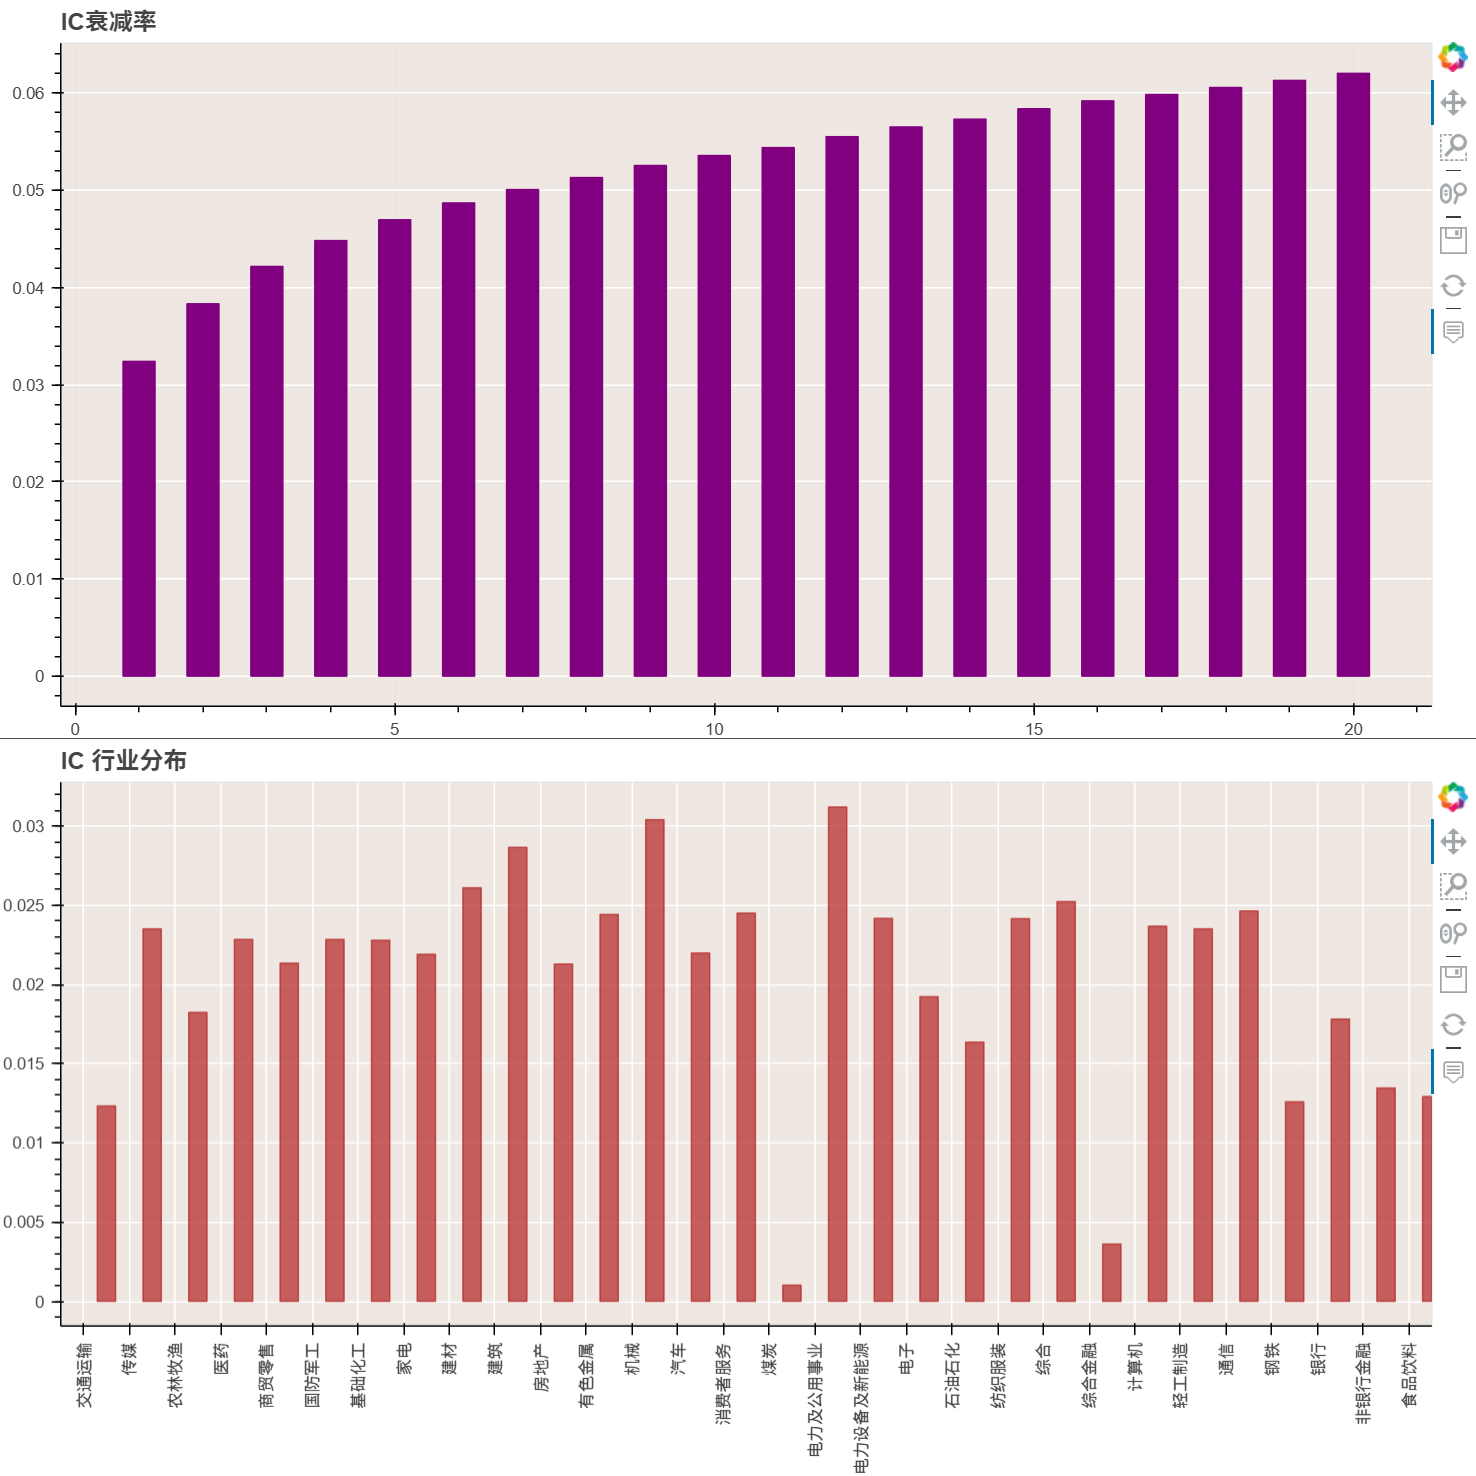

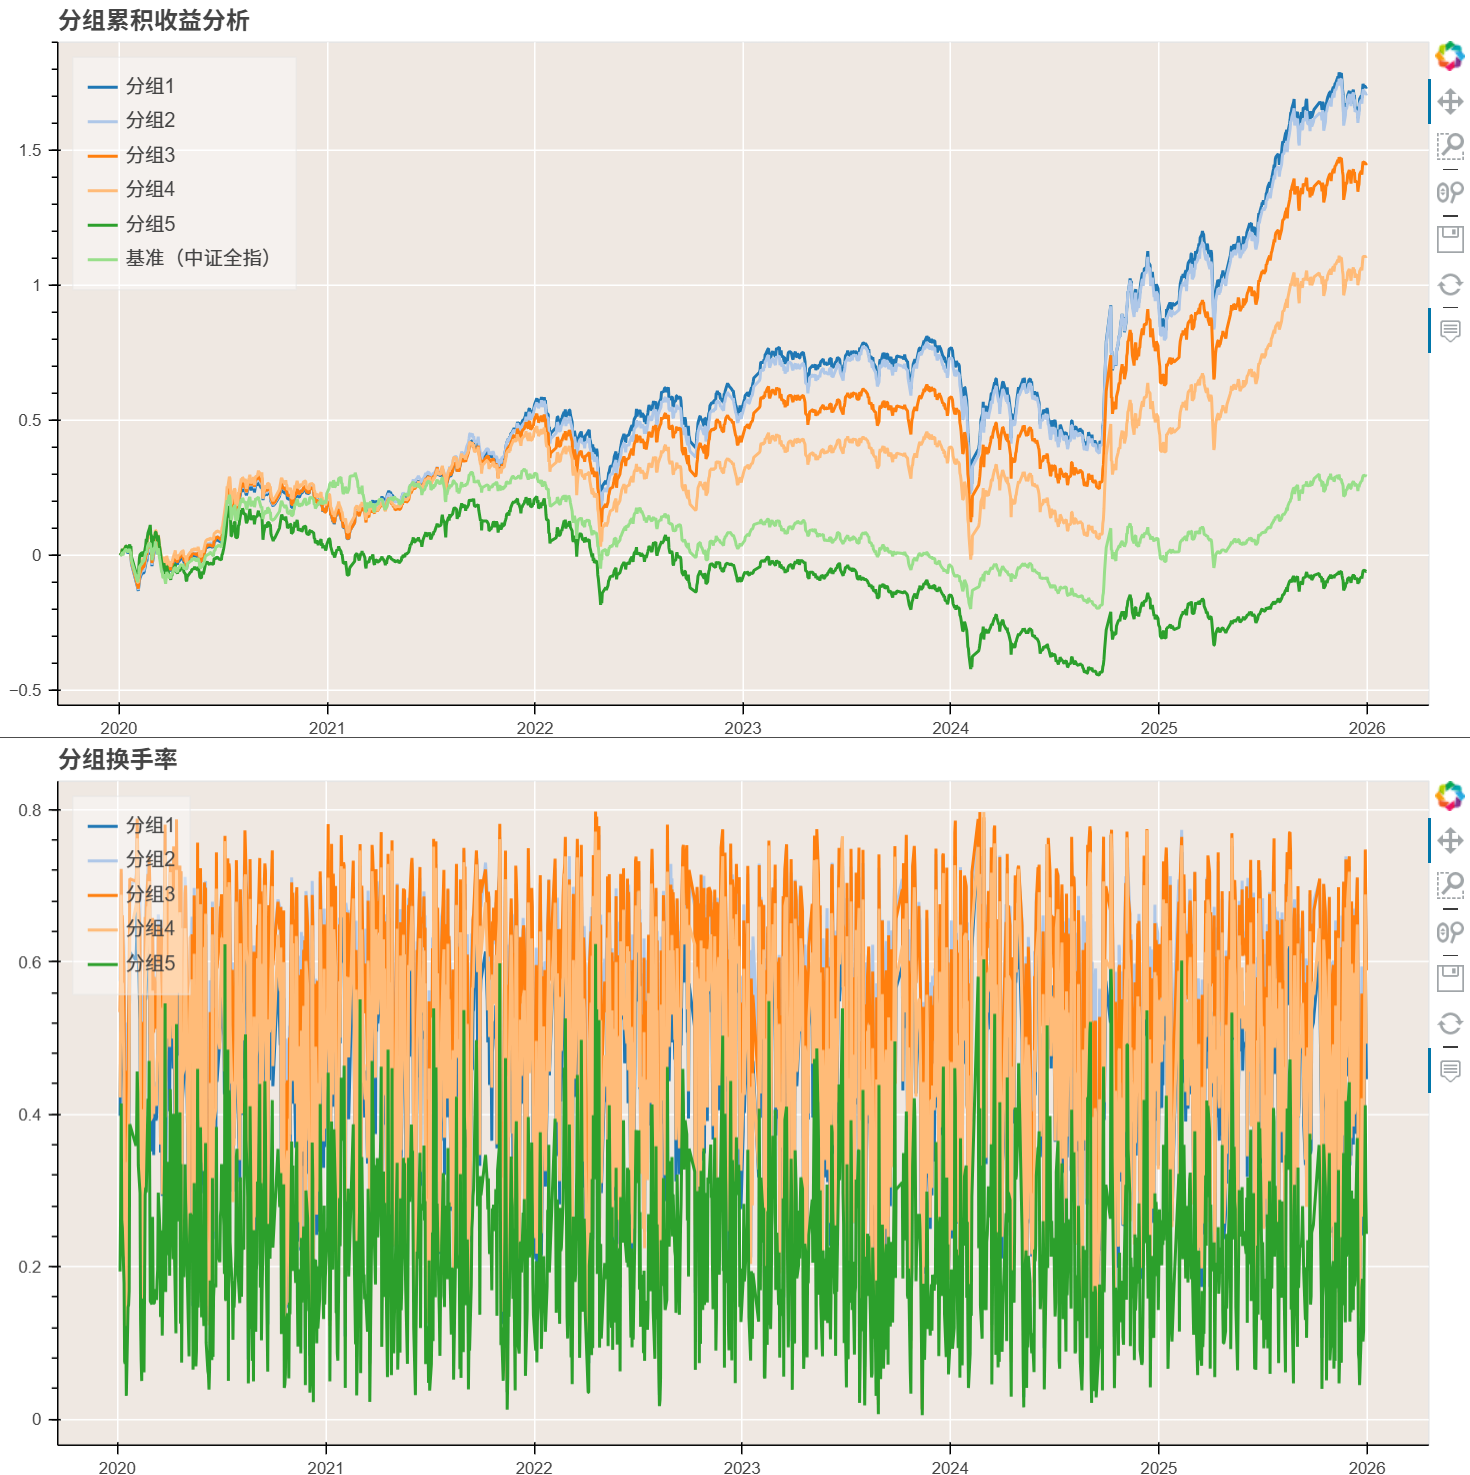

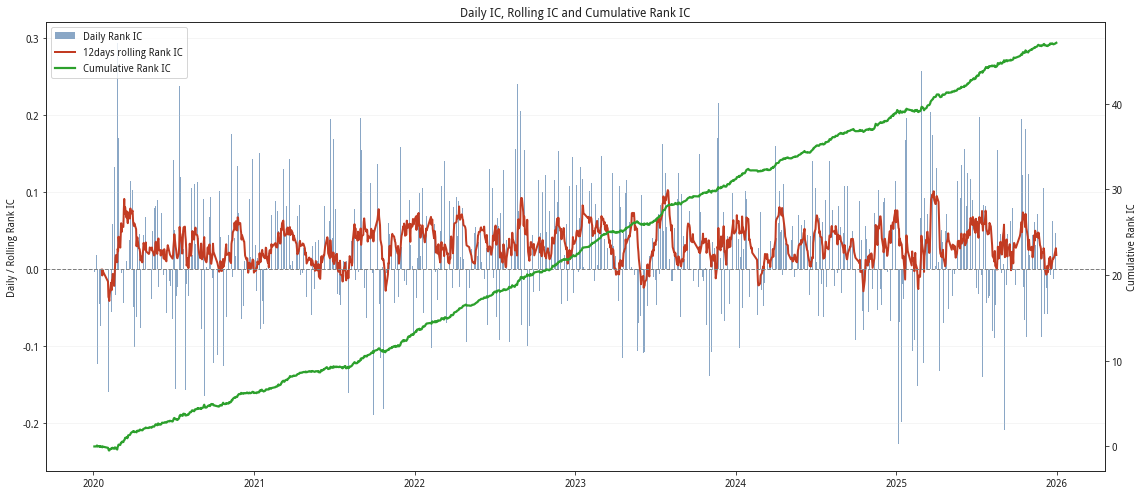

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_mkt_turnover_beta.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()